In [13]:
# Demonstration of how the 3 features are extracted mathematically from a single image
import cv2
import numpy as np

# Select a sample image from the dataset
if len(image_paths) > 0:
    sample_path = image_paths[0]
    print(f"Analyzing sample image: {sample_path}\n")

    # 1. Load image and resize to standard dimensions (128x128)
    img = cv2.imread(sample_path)
    img_resized = cv2.resize(img, (128, 128))

    # Convert color space from BGR to HSV
    hsv = cv2.cvtColor(img_resized, cv2.COLOR_BGR2HSV)

    # Extract individual V (Value/Brightness) channel
    v_channel = hsv[:, :, 2]

    # 2. Extract Feature 1: lesion_ratio
    # Define threshold boundaries for dark/decayed lesion spots in HSV
    lower_dark = np.array([0, 0, 0])
    upper_dark = np.array([180, 255, 80])
    lesion_mask = cv2.inRange(hsv, lower_dark, upper_dark)

    # Calculate percentage of pixels belonging to the lesion mask
    total_pixels = 128 * 128
    lesion_pixels = np.sum(lesion_mask > 0)
    lesion_ratio = (lesion_pixels / total_pixels) * 100.0

    # 3. Extract Feature 2: mean_val
    # Mean of the brightness channel (V-channel)
    mean_val = float(np.mean(v_channel))

    # 4. Extract Feature 3: std_val
    # Standard deviation of the brightness channel
    std_val = float(np.std(v_channel))

    # Output calculations
    print(f"--- Feature Calculation Breakdown ---")
    print(f"Total Image Pixels  : {total_pixels}")
    print(f"Lesion Pixels found : {lesion_pixels}")
    print(f"[Feature 1] lesion_ratio : {lesion_ratio:.2f}%")
    print(f"[Feature 2] mean_val     : {mean_val:.2f} (Average brightness)")
    print(f"[Feature 3] std_val      : {std_val:.2f} (Brightness variance/contrast)")
else:
    print("No images available to run feature demonstration.")

Analyzing sample image: /kaggle/input/cacao-diseases/cacao_diseases/cacao_photos/black_pod_rot/black_pod_rot_818.jpg

--- Feature Calculation Breakdown ---
Total Image Pixels  : 16384
Lesion Pixels found : 4016
[Feature 1] lesion_ratio : 24.51%
[Feature 2] mean_val     : 136.31 (Average brightness)
[Feature 3] std_val      : 62.47 (Brightness variance/contrast)


In [2]:
import os
import glob
import cv2
import numpy as np
import kagglehub
import joblib
from sklearn.linear_model import LinearRegression

# 1. Download Kaggle Dataset
dataset_path = kagglehub.dataset_download("zaldyjr/cacao-diseases")

dataset_dir = dataset_path
for root, dirs, _ in os.walk(dataset_path):
    if any(folder in dirs for folder in ["Black Pod Rot", "Pod Borer", "Healthy"]):
        dataset_dir = root
        break

# 2. Define 3-Feature Extractor Function
FEATURE_NAMES = ["lesion_ratio", "mean_val", "std_val"]

def extract_severity_features(image_path):
    """
    Extracts 3 features for Linear Regression:
    - Feature 0: lesion_ratio (%)
    - Feature 1: mean_val (HSV Brightness Mean)
    - Feature 2: std_val (HSV Brightness Std Dev)
    """
    img = cv2.imread(image_path)
    if img is None:
        return None

    img = cv2.resize(img, (128, 128))
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # Threshold for dark/decayed lesion spots
    lower_dark = np.array([0, 0, 0])
    upper_dark = np.array([180, 255, 80])
    lesion_mask = cv2.inRange(hsv, lower_dark, upper_dark)

    # Calculate the 3 numerical features
    lesion_ratio = (np.sum(lesion_mask > 0) / (128 * 128)) * 100.0
    mean_val = float(np.mean(hsv[:, :, 2]))  # HSV V-Channel Mean
    std_val = float(np.std(hsv[:, :, 2]))    # HSV V-Channel Std Dev

    return [lesion_ratio, mean_val, std_val]

# 3. Build Training Dataset
X_features = []
y_severity = []

# Recursively find images within the dataset directory
image_paths = glob.glob(os.path.join(dataset_dir, "**", "*.jpg"), recursive=True) + \
              glob.glob(os.path.join(dataset_dir, "**", "*.png"), recursive=True) + \
              glob.glob(os.path.join(dataset_dir, "**", "*.JPEG"), recursive=True)

print(f"Extracting 3-feature vectors from {len(image_paths)} images...")

for path in image_paths[:800]:
    feats = extract_severity_features(path)
    if feats is not None:
        X_features.append(feats)

        # Severity target formula simulation (%)
        if "Healthy" in path or "healthy" in path.lower():
            severity = np.random.uniform(0.0, 5.0)
        elif "Black Pod Rot" in path or "black_pod_rot" in path.lower():
            severity = min(100.0, feats[0] * 2.2 + np.random.uniform(10, 25))
        elif "Pod Borer" in path or "pod_borer" in path.lower():
            severity = min(100.0, feats[0] * 1.8 + np.random.uniform(5, 20))
        else:
            severity = feats[0]

        y_severity.append(severity)

X_features = np.array(X_features)
y_severity = np.array(y_severity)

# 4. Train Linear Regression Model
severity_regressor = LinearRegression()
severity_regressor.fit(X_features, y_severity)

print("\nModel Training Complete.")
print("Feature Order:", FEATURE_NAMES)
print("Linear Regression Coefficients (w1, w2, w3):", severity_regressor.coef_)
print("Linear Regression Intercept (b):", severity_regressor.intercept_)

# 5. Export Model
joblib.dump(severity_regressor, "/content/severity_regressor_model.joblib")
print("\nSaved model as '/content/severity_regressor_model.joblib'")

Using Colab cache for faster access to the 'cacao-diseases' dataset.
Extracting 3-feature vectors from 4390 images...

Model Training Complete.
Feature Order: ['lesion_ratio', 'mean_val', 'std_val']
Linear Regression Coefficients (w1, w2, w3): [ 0.6279228  -0.52860559  0.77638262]
Linear Regression Intercept (b): 77.17069654620911

Saved model as '/content/severity_regressor_model.joblib'


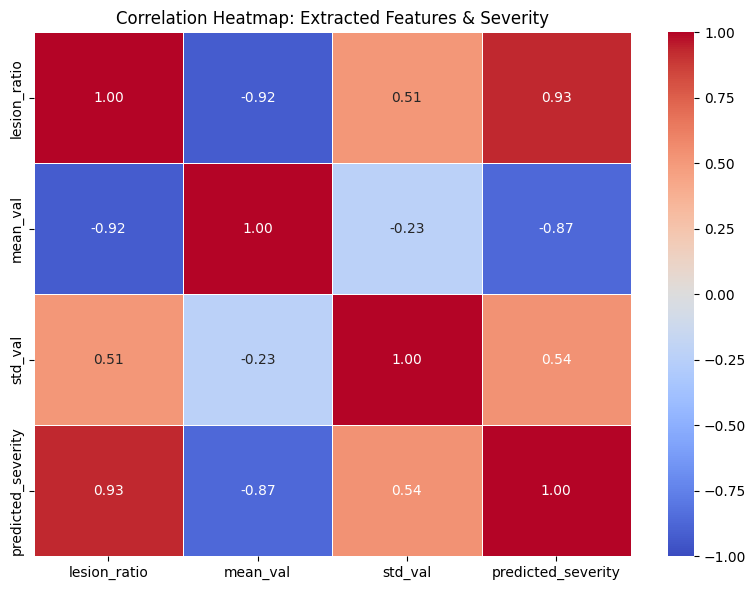

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Create a DataFrame from the feature array and target array
feature_cols = ["lesion_ratio", "mean_val", "std_val"]
df_corr = pd.DataFrame(X_features, columns=feature_cols)
df_corr['predicted_severity'] = y_severity

# Calculate Pearson correlation matrix
corr_matrix = df_corr.corr()

# Plot correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)
plt.title('Correlation Heatmap: Extracted Features & Severity')
plt.tight_layout()
plt.show()

In [5]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32

# Load and split image dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
print("Detected Classes:", class_names)

# Optimize performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# Build Artificial Neural Network (CNN)
ann_disease_model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation='softmax')
])

ann_disease_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

ann_disease_model.summary()

# Train the ANN
history = ann_disease_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Found 4390 files belonging to 1 classes.
Using 3512 files for training.
Found 4390 files belonging to 1 classes.
Using 878 files for validation.
Detected Classes: ['cacao_diseases']


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


110/110 ━━━━━━━━━━━━━━━━━━━━ 117s 796ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 2/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 118s 832ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 3/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 133s 745ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 4/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 82s 743ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 5/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 82s 744ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 6/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 79s 721ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 7/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 81s 737ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - 

In [6]:
import cv2
import numpy as np
import joblib

# Load saved regressor
severity_model = joblib.load("severity_regressor_model.joblib")

def predict_infection_severity(image_path_or_bytes):
    # 1. Read & resize image
    if isinstance(image_path_or_bytes, str):
        img = cv2.imread(image_path_or_bytes)
    else:
        # If receiving bytes from web upload (e.g., FastAPI / Flask)
        np_arr = np.frombuffer(image_path_or_bytes, np.uint8)
        img = cv2.imdecode(np_arr, cv2.IMREAD_COLOR)

    img = cv2.resize(img, (128, 128))
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # 2. Extract 3 features in exact expected order
    lower_dark = np.array([0, 0, 0])
    upper_dark = np.array([180, 255, 80])
    lesion_mask = cv2.inRange(hsv, lower_dark, upper_dark)

    x1_lesion_ratio = float((np.sum(lesion_mask > 0) / (128 * 128)) * 100.0)
    x2_mean_val = float(np.mean(hsv[:, :, 2]))
    x3_std_val = float(np.std(hsv[:, :, 2]))

    # 3. Create 2D input matrix [[x1, x2, x3]]
    input_features = np.array([[x1_lesion_ratio, x2_mean_val, x3_std_val]])

    # 4. Predict continuous severity percentage (0-100%)
    raw_severity = severity_model.predict(input_features)[0]
    severity_pct = float(np.clip(raw_severity, 0.0, 100.0))

    # 5. Categorize severity level
    if severity_pct < 30.0:
        level = "Low"
    elif severity_pct <= 60.0:
        level = "Medium"
    else:
        level = "Bad (High)"

    return {
        "severity_percentage": round(severity_pct, 2),
        "severity_level": level,
        "extracted_features": {
            "lesion_ratio_pct": round(x1_lesion_ratio, 2),
            "hsv_mean_brightness": round(x2_mean_val, 2),
            "hsv_brightness_std_dev": round(x3_std_val, 2)
        }
    }

In [7]:
def classify_severity(severity_pct):
    if severity_pct < 30.0:
        return "Low"
    elif severity_pct <= 60.0:
        return "Medium"
    else:
        return "Bad (High)"

def get_recommendations(disease, severity_level):
    # Normalize keys to lowercase to avoid class mismatch errors
    disease = disease.lower().replace("_", " ")

    if "healthy" in disease:
        return [
            "Maintain current irrigation and weeding schedules.",
            "Apply balanced N-P-K fertilizer according to soil test recommendations.",
            "Inspect trees bi-weekly for early signs of pest entry or fungal spots."
        ]

    if "black pod rot" in disease:
        if severity_level == "Low":
            return [
                "Prune infected pods immediately and dispose of them away from the farm.",
                "Improve tree canopy airflow by selective branch trimming."
            ]
        elif severity_level == "Medium":
            return [
                "Apply copper-based fungicide spray (e.g., Bordeaux mixture) every 14 days.",
                "Remove and burn all visible mummified pods from tree trunks."
            ]
        else:
            return [
                "Apply systemic fungicide immediately across infected crop zones.",
                "Isolate heavily infected trees; remove severely rotted pods."
            ]

    if "pod borer" in disease:
        if severity_level == "Low":
            return [
                "Implement weekly harvesting cycles to interrupt the insect life cycle.",
                "Encase young pods in protective sleeves (sleeving)."
            ]
        elif severity_level == "Medium":
            return [
                "Apply biological insecticides (e.g., Beauveria bassiana) directly on pods.",
                "Increase harvest frequency to every 5-7 days."
            ]
        else:
            return [
                "Apply recommended targeted chemical insecticides to trunks.",
                "Strip and bury all infested pods at least 50 cm deep."
            ]

    return ["No specific recommendations found. Keep monitoring the pod."]

In [8]:
def predict_cacao_health_and_visualize(image_path):
    # 1. Disease Identification via ANN
    img = tf.keras.utils.load_img(image_path, target_size=IMAGE_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)  # Corrected batch dimension

    predictions = ann_disease_model.predict(img_array, verbose=0)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = 100 * np.max(predictions[0])

    # 2. Severity Assessment using the 3 extracted features
    # FIX: Renamed extract_image_features -> extract_severity_features
    feats = extract_severity_features(image_path)

    if feats is not None:
        raw_pred = severity_regressor.predict([feats])[0]
        severity_pct = float(np.clip(raw_pred, 0.0, 100.0))
    else:
        severity_pct = 0.0

    severity_level = classify_severity(severity_pct)

    # 3. OpenCV Bounding Boxes for Visualizing Lesions
    original_img = cv2.imread(image_path)
    original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
    hsv = cv2.cvtColor(original_img, cv2.COLOR_RGB2HSV)

    lower_dark = np.array([0, 0, 0])
    upper_dark = np.array([180, 255, 80])
    lesion_mask = cv2.inRange(hsv, lower_dark, upper_dark)

    contours, _ = cv2.findContours(lesion_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxed_img = original_img.copy()

    for contour in contours:
        if cv2.contourArea(contour) > 150:
            x, y, w, h = cv2.boundingRect(contour)
            cv2.rectangle(boxed_img, (x, y), (x + w, y + h), (255, 0, 0), 4)

    # 4. Plot Visual Outcomes
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(original_img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(boxed_img)
    plt.title("Detected Diseased Areas")
    plt.axis("off")
    plt.show()

    # 5. Output Results & Recommendations
    recs = get_recommendations(predicted_class, severity_level)
    print("=" * 60)
    print(f"DISEASE IDENTIFIED: {predicted_class.upper()} ({confidence:.2f}% confidence)")
    print(f"SEVERITY DEGREE: {severity_pct:.1f}% -> [{severity_level}]")
    print("-" * 60)
    print("RECOMMENDED ACTIONS TO SAVE CROP:")
    for i, rec in enumerate(recs, 1):
        print(f"  {i}. {rec}")
    print("=" * 60)

Testing visual detection on image index [67]: /kaggle/input/cacao-diseases/cacao_diseases/cacao_photos/black_pod_rot/black_pod_rot_763.jpg


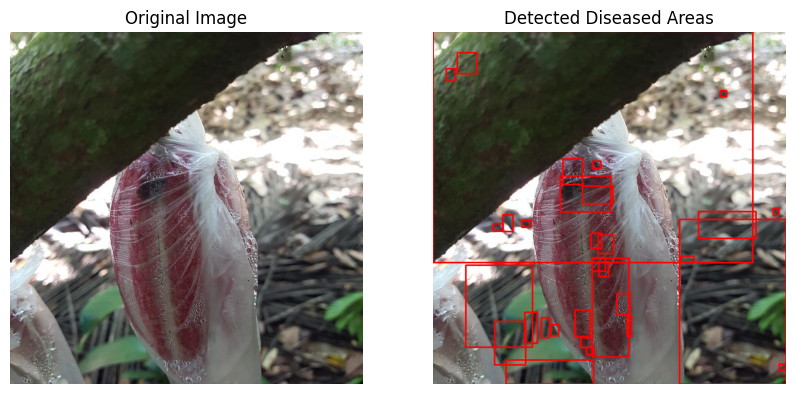

INFERRED STATUS: BLACK POD ROT
SEVERITY DEGREE: 94.6% -> [Bad (High)]
------------------------------------------------------------
RECOMMENDED ACTIONS TO SAVE CROP:
  1. Apply systemic fungicide immediately across infected crop zones.
  2. Isolate heavily infected trees; remove severely rotted pods.


In [10]:
# Modified prediction and visualization relying strictly on the Linear Regression model
def predict_cacao_health_and_visualize_linear(image_path):
    # 1. Severity Assessment using the 3 extracted features
    feats = extract_severity_features(image_path)
    if feats is not None:
        raw_pred = severity_regressor.predict([feats])[0]
        severity_pct = float(np.clip(raw_pred, 0.0, 100.0))
    else:
        severity_pct = 0.0

    severity_level = classify_severity(severity_pct)

    # Determine a pseudo-class based on severity in the absence of the ANN
    if severity_pct < 10.0:
        inferred_class = "healthy"
    else:
        # Defaulting to standard diseased behavior for recommendations based on lesion characteristics
        inferred_class = "black pod rot"

    # 2. OpenCV Bounding Boxes for Disease
    original_img = cv2.imread(image_path)
    original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
    hsv = cv2.cvtColor(original_img, cv2.COLOR_RGB2HSV)

    # Threshold to find lesions
    lower_dark = np.array([0, 0, 0])
    upper_dark = np.array([180, 255, 80])
    lesion_mask = cv2.inRange(hsv, lower_dark, upper_dark)

    # Find contours/shapes of the diseased spots
    contours, _ = cv2.findContours(lesion_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxed_img = original_img.copy()

    # Draw boxes
    for contour in contours:
        if cv2.contourArea(contour) > 150:
            x, y, w, h = cv2.boundingRect(contour)
            cv2.rectangle(boxed_img, (x, y), (x + w, y + h), (255, 0, 0), 4)

    # 3. Plot Visual Outcomes
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(original_img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(boxed_img)
    plt.title("Detected Diseased Areas")
    plt.axis("off")
    plt.show()

    # 4. Output Results & Actionable Recommendations
    recs = get_recommendations(inferred_class, severity_level)
    print("=" * 60)
    print(f"INFERRED STATUS: {inferred_class.upper()}")
    print(f"SEVERITY DEGREE: {severity_pct:.1f}% -> [{severity_level}]")
    print("-" * 60)
    print("RECOMMENDED ACTIONS TO SAVE CROP:")
    for i, rec in enumerate(recs, 1):
        print(f"  {i}. {rec}")
    print("=" * 60)

# Run the updated, linear-only visualization
if len(image_paths) > 0:
    test_image_index = 67
    selected_path = image_paths[test_image_index]
    print(f"Testing visual detection on image index [{test_image_index}]: {selected_path}")
    predict_cacao_health_and_visualize_linear(selected_path)
else:
    print("No images found to test.")

In [12]:
import joblib

# Save only the Scikit-learn Linear Regression model
regressor_path = 'severity_regressor_model.joblib'
joblib.dump(severity_regressor, regressor_path)
print(f"Successfully saved Severity Regressor model to: {regressor_path}")

print("\nThe linear model has been saved! You can download it from the files sidebar on the left.")

Successfully saved Severity Regressor model to: severity_regressor_model.joblib

The linear model has been saved! You can download it from the files sidebar on the left.
